In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from collections import Counter

In [5]:
file_path = "/content/online_retail_II.xlsx"

df1 = pd.read_excel(file_path, sheet_name="Year 2009-2010")
df2 = pd.read_excel(file_path, sheet_name="Year 2010-2011")

df = pd.concat([df1, df2], ignore_index=True)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [6]:
# Remove invalid and cancelled purchases
df.columns = df.columns.str.strip()
df["Invoice"] = df["Invoice"].astype("string").str.strip()
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")

df = df.dropna(subset=["Invoice", "StockCode", "Description", "Quantity"])
df = df[~df["Invoice"].str.upper().str.startswith("C", na=False)]
df = df[df["Quantity"] > 0].copy()

# Remove duplicate product lines
df = df.drop_duplicates(subset=["Invoice", "StockCode"])
df = df[df["Description"].astype(str).str.strip().ne("")]

print("Cleaned rows:", len(df))

Cleaned rows: 997479


In [7]:
# Group products by invoice
basket = df.groupby("Invoice")["StockCode"].apply(
    lambda x: sorted(set(x.astype(str)))
)

print("Total orders:", len(basket))
display(basket.head())

Total orders: 40301


,StockCode
Invoice,
489434,"[21232, 21523, 21871, 22041, 22064, 79323P, 79..."
489435,"[22195, 22349, 22350, 22353]"
489436,"[21181, 21333, 21754, 21755, 21756, 22107, 221..."
489437,"[10002, 20695, 20703, 20971, 21351, 21352, 213..."
489438,"[20711, 21033, 21100, 21252, 21329, 21410, 214..."


In [8]:
# Count pairs appearing in the same invoice
pair_counts = Counter()

for products in basket:
    if len(products) >= 2:
        pair_counts.update(combinations(products, 2))

pairs_df = pd.DataFrame([
    {
        "Product1": pair[0],
        "Product2": pair[1],
        "OrdersTogether": count
    }
    for pair, count in pair_counts.items()
])

pairs_df = pairs_df.sort_values(
    "OrdersTogether", ascending=False
).reset_index(drop=True)

display(pairs_df.head(20))

,Product1,Product2,OrdersTogether
0,22386,85099B,1426
1,21931,85099B,1324
2,21733,85123A,1234
3,20725,20727,1202
4,21212,84991,1197
5,85099B,85099F,1185
6,20725,22383,1177
7,22411,85099B,1158
8,20725,22384,1156
9,21212,21977,1111


In [9]:
# Map product codes to descriptions
product_names = (
    df.assign(StockCode=df["StockCode"].astype(str))
    .drop_duplicates("StockCode")
    .set_index("StockCode")["Description"]
    .to_dict()
)

pairs_df["Product1_Name"] = pairs_df["Product1"].map(product_names)
pairs_df["Product2_Name"] = pairs_df["Product2"].map(product_names)

top_pairs = pairs_df[
    ["Product1_Name", "Product2_Name", "OrdersTogether"]
].head(20)

display(top_pairs)

,Product1_Name,Product2_Name,OrdersTogether
0,JUMBO BAG PINK WITH WHITE SPOTS,JUMBO BAG RED WHITE SPOTTY,1426
1,JUMBO STORAGE BAG SUKI,JUMBO BAG RED WHITE SPOTTY,1324
2,RED HANGING HEART T-LIGHT HOLDER,WHITE HANGING HEART T-LIGHT HOLDER,1234
3,LUNCH BAG RED SPOTTY,LUNCH BAG BLACK SKULL.,1202
4,PACK OF 72 RETRO SPOT CAKE CASES,60 TEATIME FAIRY CAKE CASES,1197
5,JUMBO BAG RED WHITE SPOTTY,JUMBO BAG STRAWBERRY,1185
6,LUNCH BAG RED SPOTTY,LUNCHBAG SUKI DESIGN,1177
7,JUMBO SHOPPER VINTAGE RED PAISLEY,JUMBO BAG RED WHITE SPOTTY,1158
8,LUNCH BAG RED SPOTTY,LUNCHBAG PINK RETROSPOT,1156
9,PACK OF 72 RETRO SPOT CAKE CASES,PACK OF 60 PINK PAISLEY CAKE CASES,1111


In [10]:
# Recommend products frequently bought with a selected product
def recommend_products(product_code, top_n=5):
    product_code = str(product_code)

    recs = pairs_df[
        (pairs_df["Product1"] == product_code) |
        (pairs_df["Product2"] == product_code)
    ].copy()

    recs["RecommendedCode"] = recs.apply(
        lambda r: r["Product2"]
        if r["Product1"] == product_code else r["Product1"],
        axis=1
    )

    recs = recs.drop_duplicates("RecommendedCode")
    recs = recs.sort_values("OrdersTogether", ascending=False)

    recs["RecommendedProduct"] = recs["RecommendedCode"].map(product_names)

    return recs[
        ["RecommendedProduct", "OrdersTogether"]
    ].head(top_n)


# Test with a product from the top pair
if not pairs_df.empty:
    code = pairs_df.iloc[0]["Product1"]
    display(recommend_products(code))
else:
    print("No product pairs found.")

,RecommendedProduct,OrdersTogether
0,JUMBO BAG RED WHITE SPOTTY,1426
31,JUMBO STORAGE BAG SUKI,900
41,JUMBO SHOPPER VINTAGE RED PAISLEY,843
67,JUMBO BAG STRAWBERRY,759
90,JUMBO BAG BAROQUE BLACK WHITE,716


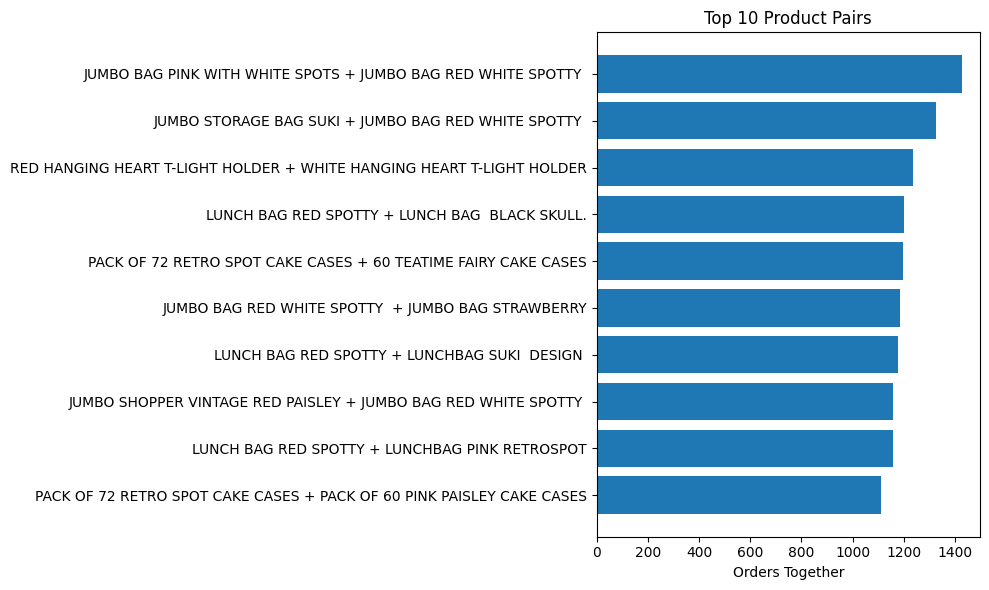

In [11]:
# Visualize the most frequent product pairs
top10 = pairs_df.head(10).copy()

top10["Pair"] = (
    top10["Product1_Name"].fillna(top10["Product1"])
    + " + "
    + top10["Product2_Name"].fillna(top10["Product2"])
)

top10 = top10.sort_values("OrdersTogether")

plt.figure(figsize=(10, 6))
plt.barh(top10["Pair"], top10["OrdersTogether"])
plt.title("Top 10 Product Pairs")
plt.xlabel("Orders Together")
plt.tight_layout()
plt.show()

In [12]:
top_pairs.to_csv("top_product_pairs.csv", index=False)
pairs_df.to_csv("all_product_pairs.csv", index=False)

print("Analysis completed successfully!")
print("Top product pairs and recommendations are ready.")

Analysis completed successfully!
Top product pairs and recommendations are ready.
